In [3]:

# Install IBL ONE API
%pip -q install -U ONE-api

from one.api import ONE
import pandas as pd
import numpy as np

# Connect using the public IBL credentials
one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True
)

PROJECT = "angelaki_mouseASD"
RELEASE = "2025_Q3_Noel_et_al_Autism"

print("Connected to IBL OpenAlyx")
print("Project:", PROJECT)
print("Release:", RELEASE)


Connected to IBL OpenAlyx
Project: angelaki_mouseASD
Release: 2025_Q3_Noel_et_al_Autism


In [4]:

# Find all probe insertions belonging to the Angelaki ASD project
insertions = one.search_insertions(project=PROJECT)

print("Total probe insertions:", len(insertions))
print("First five insertion IDs:")
for pid in insertions[:5]:
    print(pid)

# Keep the insertion list for the next steps
pids = [str(pid) for pid in insertions]


/usr/local/lib/python3.13/dist-packages/one/webclient.py:1053: RuntimeWarning: The shared public account will be retired soon. Register your own account at https://openalyx.internationalbrainlab.org/signup
  emit(message)


Total probe insertions: 364
First five insertion IDs:
71275b79-12f3-42a0-8963-43f6381fbd4a
a24cad0d-9d17-472c-aac2-f5ee4a126bb5
8a05e4d5-a860-4947-81d5-9a2c90779d44
617f42c7-9580-4f25-a466-ec8989d89452
c4a5fed9-ff3b-4b73-8a79-38ba966c0093


In [5]:

# Select one example probe insertion
pid = pids[0]

# Read insertion metadata without downloading raw signals
insertion_info = one.alyx.rest(
    "insertions", "read", id=pid
)

print("Insertion ID:", pid)
print("Probe name:", insertion_info.get("name"))

# Resolve the associated session
session_ref = insertion_info.get("session")
eid = (
    session_ref.split("/")[-2]
    if isinstance(session_ref, str) and "/" in session_ref
    else str(session_ref)
)

print("Session ID:", eid)

# List available files (metadata only)
datasets = one.list_datasets(
    eid, details=True
)

df = pd.DataFrame(datasets)

print("Total dataset entries:", len(df))
print("Available columns:", df.columns.tolist())

display(df.head(10))


Insertion ID: 71275b79-12f3-42a0-8963-43f6381fbd4a
Probe name: probe00
Session ID: 3da15f76-b31b-4ca7-a25c-c46cb8e40a06
Total dataset entries: 127
Available columns: ['file_size', 'hash', 'exists', 'rel_path', 'default_revision', 'qc']


,file_size,hash,exists,rel_path,default_revision,qc
id,,,,,,
02c09856-5183-401e-977e-101b94694166,86640,292e611afefee0d24bc93e7e45b2800d,True,raw_ephys_data/probe01/_spikeglx_sync.polariti...,True,NOT_SET
043642a1-de53-4eb3-a913-1922461f6e93,13900456,11eb9ba41106ef32b55243dd52be1f63,True,alf/_ibl_wheel.timestamps.npy,True,NOT_SET
0598f25b-fa55-4b77-8e6d-487b0224ce31,86640,3ca33ded4d6b5fc4dcc2a7a17f69e2b1,True,raw_ephys_data/probe00/_spikeglx_sync.times.pr...,True,NOT_SET
0778952c-5693-420b-9b52-af168406aac6,37000368,d52bff48b96dddc235b022f6b96688f0,True,alf/probe01/pykilosort/spikes.samples.npy,True,NOT_SET
08b47448-9564-4958-b7d9-96974663d2c0,26434960,5c64643d163456c0bcd7e1ab643b6e02,True,alf/probe00/pykilosort/spikes.amps.npy,True,NOT_SET
0a3a82af-cf08-40ed-b075-1e7a9fd4084d,33386,0c232d2e5e6f5b7b1276b5d31ea77984,True,alf/probe00/pykilosort/#2024-03-12#/clusters.m...,False,NOT_SET
0f644cfd-ed29-4980-91d3-20e0a5647675,13806,f9ad7f0a697b84d3a20e5f09f5b1d43b,True,alf/probe01/pykilosort/clusters.uuids.csv,True,NOT_SET
11574cdc-14c4-40d5-b5f8-2ecc18e4443f,13217544,5841365092da533766f88116c32c3f7d,True,alf/probe00/pykilosort/spikes.clusters.npy,True,NOT_SET
12631122-7a61-468e-accd-de9fcae81041,3867330,83532f8396d224f141d602341f0012a0,True,alf/_ibl_bodyCamera.dlc.pqt,True,NOT_SET


In [6]:

# Search dataset metadata for continuous LF recordings
# and existing spectral summaries

df["dataset_path"] = df.get(
    "rel_path",
    pd.Series("", index=df.index)
).fillna("").astype(str)

lf_mask = df["dataset_path"].str.contains(
    r"\.lf\.|SpectralDensityLF|ephysTimeRmsLF",
    case=False,
    regex=True
)

lf_datasets = df.loc[lf_mask].copy()

print("Potential LFP-related files:", len(lf_datasets))
display(lf_datasets)


Potential LFP-related files: 14


,file_size,hash,exists,rel_path,default_revision,qc,dataset_path
id,,,,,,,
2c9239a9-5db3-42ba-b316-9c5435aeeb7a,2542668,1dc5dc4adfb7e13d5579aff7409701ec,True,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.r...,True,NOT_SET,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.r...
3bf46231-0b12-4f63-972c-80d017b9c0e6,2976804902,61db2b49b0a26b4c1025a1518b4ad34c,True,raw_ephys_data/probe00/_spikeglx_ephysData_g0_...,True,NOT_SET,raw_ephys_data/probe00/_spikeglx_ephysData_g0_...
728ac514-0788-4ff5-aacc-44c567adbc5e,2180,f3ffe62ed24d19c0979861b4308a9d00,True,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...
769884b3-f91f-4028-820e-8ee55c2e7ec5,6732,2dd9d05c37db730f0478295c292c0d4b,True,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.t...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.t...
81ecce23-d925-4772-b6ad-95cd8e9294f7,790148,70dfa3c0125be79645dcbadcec3484a7,True,raw_ephys_data/probe00/_iblqc_ephysSpectralDen...,True,NOT_SET,raw_ephys_data/probe00/_iblqc_ephysSpectralDen...
901d28ab-db2a-44bb-aa37-e97157ddffce,13904,09997db193dc51e60295f0e6f50f8e9e,True,raw_ephys_data/probe01/_spikeglx_ephysData_g0_...,True,NOT_SET,raw_ephys_data/probe01/_spikeglx_ephysData_g0_...
9e36dd4e-8ae3-4d9e-a3ee-f8fa60c16586,6732,aeaa70e86fbe700e57a30d8aa35e673f,True,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.t...,True,NOT_SET,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.t...
b72e2839-8d78-49e9-bc93-4e562a852dd7,2542668,fc53dcdae399ab3d70f3f19356456955,True,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.r...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.r...
c124fc1a-7678-42f5-b7fe-7bfaf84964e4,790148,ae958419415d176df564634a4175f321,True,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...


In [7]:

# Display complete LFP-related filenames
pd.set_option("display.max_colwidth", None)

lf_files = df[
    df["rel_path"].str.contains(
        r"\.lf\.|SpectralDensityLF|TimeRmsLF",
        case=False,
        regex=True,
        na=False
    )
].copy()

lf_files["size_MB"] = (
    lf_files["file_size"] / 1024**2
).round(2)

print("LFP-related files:")
print("Total:", len(lf_files))

for _, row in lf_files.iterrows():
    print(
        f"{row['size_MB']:>9.2f} MB | "
        f"{row['rel_path']}"
    )


LFP-related files:
Total: 14
     2.42 MB | raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.rms.npy
  2838.90 MB | raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.imec0.lf.cbin
     0.00 MB | raw_ephys_data/probe01/_iblqc_ephysSpectralDensityLF.freqs.npy
     0.01 MB | raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.timestamps.npy
     0.75 MB | raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.power.npy
     0.01 MB | raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.meta
     0.01 MB | raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.timestamps.npy
     2.42 MB | raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.rms.npy
     0.75 MB | raw_ephys_data/probe01/_iblqc_ephysSpectralDensityLF.power.npy
     0.00 MB | raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.freqs.npy
     0.15 MB | raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.ch
     0.15 MB | raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.imec0.lf.ch
     0.01 MB | raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.i

In [8]:

# Retrieve session metadata
session_info = one.alyx.rest(
    "sessions", "read", id=eid
)

print("Session ID:", eid)
print("Subject:", session_info.get("subject"))
print("Date:", session_info.get("start_time"))
print("Project:", session_info.get("projects"))
print("Number of trials:", session_info.get("n_trials"))

# Retrieve subject metadata
subject_name = session_info.get("subject")

subject_info = one.alyx.rest(
    "subjects", "read", id=subject_name
)

print("\nSubject metadata:")
for key in [
    "nickname",
    "sex",
    "birth_date",
    "genotype",
    "line",
    "strain"
]:
    print(f"{key}: {subject_info.get(key)}")


Session ID: 3da15f76-b31b-4ca7-a25c-c46cb8e40a06
Subject: FMR031
Date: 2022-03-25T10:35:25.897863
Project: ['angelaki_mouseASD']
Number of trials: 658

Subject metadata:
nickname: FMR031
sex: M
birth_date: 2021-11-16
genotype: []
line: None
strain: None


In [9]:

# Load precomputed LFP spectral density
# These files are small; raw LFP will not be downloaded.

PROBE = "probe00"

lf_psd = one.load_object(
    eid,
    "ephysSpectralDensityLF",
    collection=f"raw_ephys_data/{PROBE}"
)

print("Available PSD fields:")
print(list(lf_psd.keys()))

for key, value in lf_psd.items():
    print(
        f"{key}: shape={np.shape(value)}, "
        f"dtype={getattr(value, 'dtype', 'unknown')}"
    )

freqs = np.asarray(lf_psd["freqs"])
power = np.asarray(lf_psd["power"])

print("\nFrequency range:", freqs.min(), "-", freqs.max(), "Hz")
print("Frequency resolution:", np.median(np.diff(freqs)), "Hz")
print("PSD array shape:", power.shape)


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.power.npy: 100%|██████████| 790k/790k [00:00<00:00, 2.26MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.freqs.npy: 100%|██████████| 2.18k/2.18k [00:00<00:00, 11.7kB/s]


Available PSD fields:
['power', 'freqs']
power: shape=(513, 385), dtype=float32
freqs: shape=(513,), dtype=float32

Frequency range: 0.0 - 1250.0 Hz
Frequency resolution: 2.4414062 Hz
PSD array shape: (513, 385)


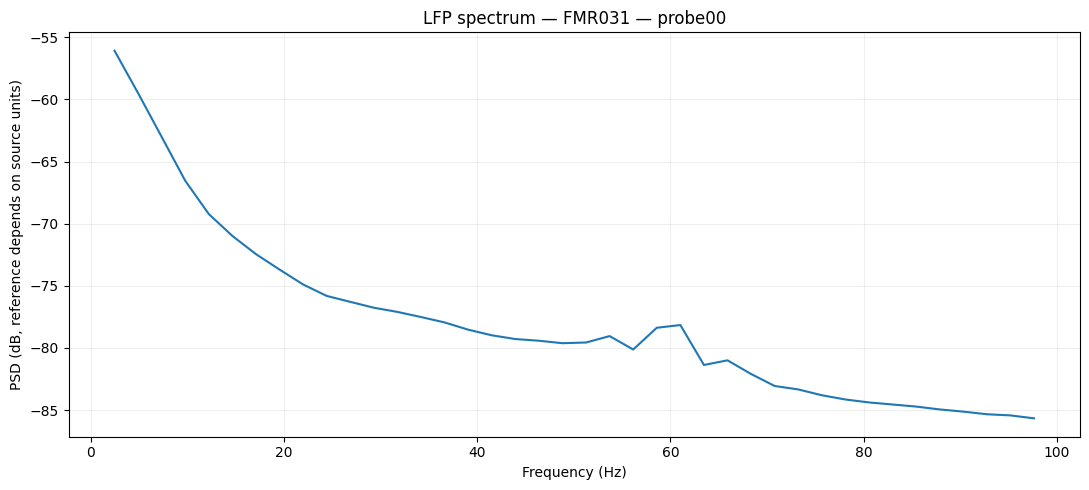

In [10]:

import matplotlib.pyplot as plt

# Detect which PSD axis contains frequency bins
if power.shape[0] == len(freqs):
    psd_by_frequency = power
elif power.shape[1] == len(freqs):
    psd_by_frequency = power.T
else:
    raise ValueError("Cannot identify frequency axis.")

# Calculate median PSD across channels for visualization
median_psd = np.nanmedian(psd_by_frequency, axis=1)

# Plot frequency spectrum
mask = (freqs >= 1) & (freqs <= 100)

plt.figure(figsize=(11, 5))
plt.plot(
    freqs[mask],
    10 * np.log10(np.maximum(median_psd[mask], 1e-30)),
    linewidth=1.5
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB, reference depends on source units)")
plt.title(f"LFP spectrum — {subject_name} — {PROBE}")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [11]:

# Download LF metadata only (not the raw .lf.cbin file)

meta_file = one.load_dataset(
    eid,
    "_spikeglx_ephysData_g0_t0.imec0.lf.meta",
    collection="raw_ephys_data/probe00",
    download_only=True
)

# Parse SpikeGLX metadata
metadata = {}

with open(meta_file, "r", encoding="utf-8-sig") as f:
    for line in f:
        if "=" in line:
            key, value = line.strip().split("=", 1)
            metadata[key] = value

print("Sampling rate:", metadata.get("imSampRate"), "Hz")
print("Channels saved:", metadata.get("nSavedChans"))
print("Recording duration:", metadata.get("fileTimeSecs"), "s")
print("Probe type:", metadata.get("imDatPrb_type"))

print("\nOther useful metadata:")
for key in ["imAiRangeMax", "imMaxInt", "snsApLfSy"]:
    print(f"{key}: {metadata.get(key)}")


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.imec0.lf.meta: 100%|██████████| 13.9k/13.9k [00:00<00:00, 101kB/s]

Sampling rate: 2500 Hz
Channels saved: 385
Recording duration: 5406.7384 s
Probe type: 0

Other useful metadata:
imAiRangeMax: 0.6
imMaxInt: None
snsApLfSy: 0,384,1


In [12]:

# Inspect anatomical channel datasets for both probes.
# Metadata only: no raw electrophysiology downloads.

channel_files = df[
    df["rel_path"].str.contains(
        r"channels\.|electrodeSites|probes\.",
        case=False,
        regex=True,
        na=False
    )
].copy()

channel_files["size_KB"] = (
    channel_files["file_size"] / 1024
).round(1)

print("Anatomical/channel datasets:")
print("Total:", len(channel_files))

for _, row in channel_files.iterrows():
    print(
        f"{row['size_KB']:>9.1f} KB | "
        f"{row['rel_path']}"
    )

print("\nCurrent insertion metadata:")
print("Probe:", insertion_info.get("name"))
print("Histology:", insertion_info.get("json"))
print("QC:", insertion_info.get("qc"))


Anatomical/channel datasets:
Total: 30
      3.1 KB | alf/probe00/electrodeSites.localCoordinates.npy
      3.1 KB | raw_ephys_data/probe01/_iblqc_ephysChannels.rawSpikeRates.npy
      3.1 KB | alf/probe00/electrodeSites.brainLocationIds_ccf_2017.npy
      3.1 KB | raw_ephys_data/probe01/_iblqc_ephysChannels.labels.npy
     46.8 KB | alf/probe01/pykilosort/clusters.waveformsChannels.npy
      4.6 KB | alf/probe00/pykilosort/channels.mlapdv.npy
      3.1 KB | raw_ephys_data/probe00/_iblqc_ephysChannels.rawSpikeRates.npy
      3.1 KB | alf/probe00/pykilosort/channels.rawInd.npy
      1.7 KB | alf/probe00/pykilosort/clusters.channels.npy
     46.8 KB | alf/probe01/pykilosort/templates.waveformsChannels.npy
   1349.6 KB | alf/probe00/pykilosort/_phy_spikes_subset.channels.npy
      6.1 KB | raw_ephys_data/probe01/_iblqc_ephysChannels.apRMS.npy
     84.6 KB | raw_ephys_data/probe00/_spikeglx_sync.channels.probe00.npy
      3.1 KB | raw_ephys_data/probe00/_iblqc_ephysChannels.labels.npy
    

In [13]:

# Compare datasets available for the two simultaneous probes.

for probe in ["probe00", "probe01"]:
    probe_files = df[
        df["rel_path"].str.contains(
            f"/{probe}/",
            regex=False,
            na=False
        )
    ]

    lf_raw = probe_files[
        probe_files["rel_path"].str.endswith(
            ".lf.cbin", na=False
        )
    ]

    anatomy = probe_files[
        probe_files["rel_path"].str.contains(
            "channels.", regex=False, na=False
        )
    ]

    print(f"\n{probe}")
    print("Raw LF files:", len(lf_raw))
    print("Channel anatomy files:", len(anatomy))
    print("All associated datasets:", len(probe_files))



probe00
Raw LF files: 1
Channel anatomy files: 7
All associated datasets: 49

probe01
Raw LF files: 1
Channel anatomy files: 7
All associated datasets: 49


In [14]:

# STEP 1 — Identify DG channels in both probes

%pip -q install ibllib iblatlas

import numpy as np
import pandas as pd
from iblatlas.regions import BrainRegions

br = BrainRegions()

PROBES = ["probe00", "probe01"]
dg_channels = {}

for probe in PROBES:
    channels = one.load_object(
        eid,
        "channels",
        collection=f"alf/{probe}/pykilosort"
    )

    atlas_ids = np.asarray(
        channels["brainLocationIds_ccf_2017"]
    ).astype(int)

    raw_indices = np.asarray(
        channels["rawInd"]
    ).astype(int)

    acronyms = br.id2acronym(atlas_ids)

    assert len(raw_indices) == len(acronyms)

    # DG subregions include DG-mo, DG-sg and DG-po.
    mask = np.array([
        str(region).startswith("DG")
        for region in acronyms
    ])

    selected = raw_indices[mask]
    dg_channels[probe] = selected

    print(f"\n{probe}")
    print("DG channels:", len(selected))
    print("Raw channel indices:", selected.tolist())

    print("\nAll recorded regions:")
    print(
        pd.Series(acronyms)
        .value_counts()
        .to_string()
    )


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/channels.mlapdv.npy: 100%|██████████| 4.74k/4.74k [00:00<00:00, 36.6kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/channels.rawInd.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 25.2kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/channels.brainLocationIds_ccf_2017.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 19.3kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/channels.localCoordinates.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 35.9kB/s]



probe00
DG channels: 54
Raw channel indices: [24, 25, 26, 27, 28, 29, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81]

All recorded regions:
root     104
MB        86
DG-mo     54
POST      40
bic       40
NB        24
void      16
HPF       10
cpd        8
PRE        2


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/channels.rawInd.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 26.9kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/channels.mlapdv.npy: 100%|██████████| 4.74k/4.74k [00:00<00:00, 38.3kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/channels.localCoordinates.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 31.8kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/channels.brainLocationIds_ccf_2017.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 32.7kB/s]


probe01
DG channels: 184
Raw channel indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305]

All recorded regions:
DG-mo    108
SUB       68
DG-sg     56
MGv       40
MGd       36
MB        30
DG-po     20
root      14
ProS       6
al

In [16]:

# STEP 2A — Inspect available behavioral datasets

pd.set_option("display.max_colwidth", None)

behavior_files = df[
    df["rel_path"].str.contains(
        r"trials|wheel|wheelMoves",
        case=False,
        regex=True,
        na=False
    )
]

print("Available behavioral files:\n")

for path in sorted(behavior_files["rel_path"]):
    print(path)

# Find the trial table using the actual dataset path.
table_files = behavior_files[
    behavior_files["rel_path"].str.endswith(
        "_ibl_trials.table.pqt",
        na=False
    )
]

if len(table_files) == 0:
    print("\nNo trials.table.pqt found.")
else:
    table_path = table_files.iloc[0]["rel_path"]
    collection, filename = table_path.rsplit("/", 1)

    print("\nLoading:", table_path)

    trials = one.load_dataset(
        eid,
        filename,
        collection=collection
    )

    trials = pd.DataFrame(trials)

    print("\nNumber of trials:", len(trials))
    print("\nColumns:")
    print(trials.columns.tolist())

    display(trials.head())


Available behavioral files:

alf/_ibl_trials.goCueTrigger_times.npy
alf/_ibl_trials.intervals_bpod.npy
alf/_ibl_trials.quiescencePeriod.npy
alf/_ibl_trials.stimOffTrigger_times.npy
alf/_ibl_trials.stimOff_times.npy
alf/_ibl_trials.stimOnTrigger_times.npy
alf/_ibl_trials.table.pqt
alf/_ibl_wheel.position.npy
alf/_ibl_wheel.timestamps.npy
alf/_ibl_wheelMoves.intervals.npy
alf/_ibl_wheelMoves.peakAmplitude.npy

Loading: alf/_ibl_trials.table.pqt


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/_ibl_trials.table.pqt: 100%|██████████| 53.7k/53.7k [00:00<00:00, 314kB/s]



Number of trials: 658

Columns:
['goCue_times', 'response_times', 'choice', 'stimOn_times', 'contrastLeft', 'contrastRight', 'probabilityLeft', 'feedback_times', 'feedbackType', 'rewardVolume', 'firstMovement_times', 'intervals_0', 'intervals_1']


,goCue_times,response_times,choice,stimOn_times,contrastLeft,contrastRight,probabilityLeft,feedback_times,feedbackType,rewardVolume,firstMovement_times,intervals_0,intervals_1
0,20.506582,20.556327,1.0,20.596907,NaN,0.2500,0.5,20.559944,-1.0,0.0,20.457921,19.799920,23.130653
1,24.296270,24.652663,1.0,24.295370,1.0,NaN,0.5,24.652768,1.0,1.5,24.483921,23.763257,26.230778
2,27.562943,27.801383,1.0,27.561944,1.0,NaN,0.5,27.801486,1.0,1.5,27.398921,26.868280,29.378891
3,30.781255,31.231601,-1.0,30.780455,NaN,1.0000,0.5,31.231710,1.0,1.5,30.818921,30.098690,32.795519
4,36.647935,37.007855,-1.0,36.646868,NaN,0.0625,0.5,37.007966,1.0,1.5,36.885921,33.430623,38.562172


In [17]:

# STEP 3 — Identify candidate quiet intervals

import numpy as np
import pandas as pd

WINDOW_S = 4.0
GUARD_S = 0.5
N_WINDOWS = 5
RANDOM_SEED = 42

# Load wheel movement intervals
wheel_moves = np.asarray(
    one.load_dataset(
        eid,
        "_ibl_wheelMoves.intervals.npy",
        collection="alf"
    ),
    dtype=float
).reshape(-1, 2)

trials_sorted = trials.sort_values(
    "intervals_0"
).reset_index(drop=True)

quiet_intervals = []

for i in range(len(trials_sorted) - 1):

    current = trials_sorted.iloc[i]
    following = trials_sorted.iloc[i + 1]

    feedback = current["feedback_times"]
    next_stim = following["stimOn_times"]

    if not np.isfinite(feedback) or not np.isfinite(next_stim):
        continue

    start = float(feedback + GUARD_S)
    end = float(next_stim - GUARD_S)

    if end <= start:
        continue

    # Subtract all wheel movement intervals
    segments = [(start, end)]

    for move_start, move_end in wheel_moves:
        updated = []

        for a, b in segments:
            if move_end <= a or move_start >= b:
                updated.append((a, b))
            else:
                if move_start > a:
                    updated.append((a, move_start))
                if move_end < b:
                    updated.append((move_end, b))

        segments = updated

        if not segments:
            break

    quiet_intervals.extend(
        (a, b) for a, b in segments if b > a
    )

quiet_intervals = np.asarray(
    quiet_intervals, dtype=float
).reshape(-1, 2)

durations = quiet_intervals[:, 1] - quiet_intervals[:, 0]

print("Total quiet segments:", len(durations))

for length in [1, 2, 3, 4, 5, 8]:
    print(
        f"Segments >= {length}s:",
        int(np.sum(durations >= length))
    )

print("\nMaximum quiet duration:",
      round(float(durations.max()), 2)
      if len(durations) else 0,
      "seconds")


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/_ibl_wheelMoves.intervals.npy: 100%|██████████| 15.0k/15.0k [00:00<00:00, 107kB/s]


Total quiet segments: 810
Segments >= 1s: 259
Segments >= 2s: 120
Segments >= 3s: 6
Segments >= 4s: 0
Segments >= 5s: 0
Segments >= 8s: 0

Maximum quiet duration: 3.16 seconds


In [18]:

# STEP 4 — Random sampling of non-overlapping windows

rng = np.random.default_rng(RANDOM_SEED)

eligible = quiet_intervals[
    (quiet_intervals[:, 1] - quiet_intervals[:, 0])
    >= WINDOW_S
]

selected_windows = []

# Randomize the order of eligible segments
for idx in rng.permutation(len(eligible)):

    start, end = eligible[idx]

    # Sample a random 4-second window within the segment
    t0 = rng.uniform(start, end - WINDOW_S)
    t1 = t0 + WINDOW_S

    # Avoid overlapping selected windows
    if any(
        t0 < old_end and t1 > old_start
        for old_start, old_end in selected_windows
    ):
        continue

    selected_windows.append((t0, t1))

    if len(selected_windows) >= N_WINDOWS:
        break

selected_windows = np.asarray(
    sorted(selected_windows),
    dtype=float
).reshape(-1, 2)

print("Eligible segments:", len(eligible))
print("Selected windows:", len(selected_windows))

display(pd.DataFrame(
    selected_windows,
    columns=["start_s", "end_s"]
))


Eligible segments: 0
Selected windows: 0


,start_s,end_s


In [19]:

# STEP 4 — Reproducible sampling of 2-second quiet windows

import numpy as np
import pandas as pd

WINDOW_S = 2.0
N_WINDOWS = 30
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

eligible = quiet_intervals[
    (quiet_intervals[:, 1] - quiet_intervals[:, 0])
    >= WINDOW_S
]

selected_windows = []

# Select at most one window from each quiet segment.
# Randomize segment order to avoid selecting only early trials.
for idx in rng.permutation(len(eligible)):
    start, end = eligible[idx]

    t0 = float(rng.uniform(start, end - WINDOW_S))
    t1 = t0 + WINDOW_S

    selected_windows.append((t0, t1))

    if len(selected_windows) == N_WINDOWS:
        break

selected_windows = np.array(
    sorted(selected_windows),
    dtype=float
).reshape(-1, 2)

print("Eligible quiet segments:", len(eligible))
print("Selected windows:", len(selected_windows))
print("Total selected duration:",
      len(selected_windows) * WINDOW_S, "s")

display(pd.DataFrame(
    selected_windows,
    columns=["start_s", "end_s"]
))

assert len(selected_windows) == N_WINDOWS, (
    "Insufficient quiet segments for the pilot."
)


Eligible quiet segments: 120
Selected windows: 30
Total selected duration: 60.0 s


,start_s,end_s
0,51.013145,53.013145
1,144.579136,146.579136
2,164.526759,166.526759
3,623.039240,625.039240
4,706.465478,708.465478
5,931.587858,933.587858
6,947.570574,949.570574
7,1020.348345,1022.348345
8,1117.448046,1119.448046
9,1223.912467,1225.912467


In [20]:

# STEP 5 — Prepare LF streaming for DG-mo on probe01

from brainbox.io.one import SpikeSortingLoader
from iblatlas.regions import BrainRegions
from scipy.signal import welch
import matplotlib.pyplot as plt

PILOT_PROBE = "probe01"

# Load channel anatomical metadata.
ch = one.load_object(
    eid,
    "channels",
    collection=f"alf/{PILOT_PROBE}/pykilosort"
)

br = BrainRegions()

atlas_ids = np.asarray(
    ch["brainLocationIds_ccf_2017"]
).astype(int)

acronyms = br.id2acronym(atlas_ids)
raw_indices = np.asarray(ch["rawInd"]).astype(int)

# Restrict selection to DG molecular layer.
dg_mo_raw = np.sort(
    raw_indices[np.asarray(acronyms) == "DG-mo"]
)

assert len(dg_mo_raw) > 0, "No DG-mo channels found."

CH = int(dg_mo_raw[len(dg_mo_raw) // 2])

print("Probe:", PILOT_PROBE)
print("DG-mo contacts:", len(dg_mo_raw))
print("Selected raw channel:", CH)

# Find the insertion corresponding to probe01.
insertions_session = one.alyx.rest(
    "insertions", "list", session=eid
)

matching = [
    ins for ins in insertions_session
    if ins["name"] == PILOT_PROBE
]

assert len(matching) == 1, (
    "Expected exactly one probe01 insertion."
)

pilot_pid = matching[0]["id"]

# Stream rather than download the full LF file.
ssl = SpikeSortingLoader(pid=pilot_pid, one=one)
sr_lf = ssl.raw_electrophysiology(
    band="lf",
    stream=True
)

fs = float(sr_lf.fs)

print("LF sampling rate:", fs)
print("Available channels:", sr_lf.nc)
print("Sync channels:", sr_lf.nsync)

assert CH < sr_lf.nc - sr_lf.nsync

print("Streamer initialized successfully.")


Probe: probe01
DG-mo contacts: 108
Selected raw channel: 106
Downloading: /root/Downloads/ONE/openalyx.internationalbrainlab.org/histology/ATLAS/Needles/Allen/average_template_25.nrrd Bytes: 32998960


100%|██████████| 31.470260620117188/31.470260620117188 [00:00<00:00, 142.53it/s]


Downloading: /root/Downloads/ONE/openalyx.internationalbrainlab.org/histology/ATLAS/Needles/Allen/annotation_25.nrrd Bytes: 4035363


100%|██████████| 3.848422050476074/3.848422050476074 [00:00<00:00, 35.65it/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.ch: 100%|██████████| 156k/156k [00:00<00:00, 863kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.meta: 100%|██████████| 13.9k/13.9k [00:00<00:00, 147kB/s]

2026-11-17 18:44:45 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


LF sampling rate: 2500.0
Available channels: 385
Sync channels: 1
Streamer initialized successfully.


In [21]:

# STEP 6 — Stream three pilot LFP windows

N_TEST = 3

psd_list = []
raw_examples = []
loaded_windows = []

for t0, t1 in selected_windows[:N_TEST]:

    # Convert session clock to probe clock in seconds.
    probe_t0 = float(
        ssl.timesprobe2times(t0, direction="reverse")
    )

    s0 = int(round(probe_t0 * fs))
    s1 = s0 + int(round(WINDOW_S * fs))

    if s0 < 0:
        print("Skipped negative sample index:", s0)
        continue

    # Stream one raw channel, without the sync channel.
    signal = np.asarray(
        sr_lf[s0:s1, CH]
    ).ravel()

    if len(signal) != int(round(WINDOW_S * fs)):
        print("Skipped incomplete window:", t0)
        continue

    if not np.all(np.isfinite(signal)):
        print("Skipped non-finite signal:", t0)
        continue

    # IBL SpikeGLX reader returns voltage in V.
    signal_uv = signal * 1e6

    frequencies, psd = welch(
        signal_uv,
        fs=fs,
        window="hann",
        nperseg=len(signal_uv),
        noverlap=0,
        detrend="constant",
        scaling="density"
    )

    psd_list.append(psd)
    raw_examples.append(signal_uv)
    loaded_windows.append((t0, t1))

    print(
        f"Window {len(psd_list)}: "
        f"{t0:.2f}–{t1:.2f} s | "
        f"RMS={np.std(signal_uv):.2f} µV"
    )

assert len(psd_list) > 0, "No windows successfully loaded."

psd_array = np.vstack(psd_list)
mean_psd = np.mean(psd_array, axis=0)

print("\nPSD shape:", psd_array.shape)
print("Frequency resolution:",
      frequencies[1] - frequencies[0], "Hz")


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.timestamps.npy: 100%|██████████| 4.48k/4.48k [00:00<00:00, 32.6kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.sync.npy: 100%|██████████| 4.48k/4.48k [00:00<00:00, 31.8kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.ap.meta: 100%|██████████| 17.7k/17.7k [00:00<00:00, 84.5kB/s]


2026-11-17 18:45:01 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


Window 1: 51.01–53.01 s | RMS=107.44 µV
2026-11-17 18:45:02 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


Window 2: 144.58–146.58 s | RMS=68.03 µV
2026-11-17 18:45:03 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


Window 3: 164.53–166.53 s | RMS=93.00 µV

PSD shape: (3, 2501)
Frequency resolution: 0.5 Hz


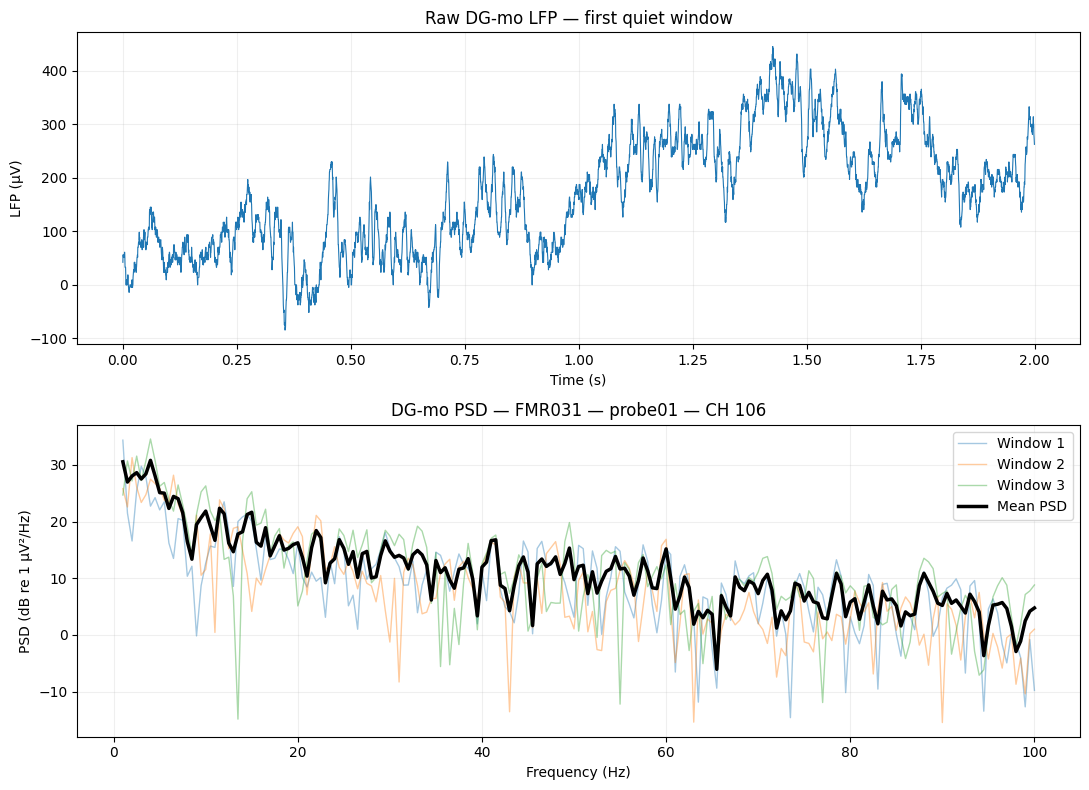

In [22]:

# STEP 7 — Plot raw LFP and power spectral density

fig, axes = plt.subplots(
    2, 1, figsize=(11, 8)
)

# Raw LFP from the first quiet window
time_axis = np.arange(len(raw_examples[0])) / fs

axes[0].plot(
    time_axis,
    raw_examples[0],
    linewidth=0.8
)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("LFP (µV)")
axes[0].set_title("Raw DG-mo LFP — first quiet window")
axes[0].grid(alpha=0.2)

# Power spectral density
mask = (frequencies >= 1) & (frequencies <= 100)

for i, psd in enumerate(psd_array):
    axes[1].plot(
        frequencies[mask],
        10 * np.log10(np.maximum(psd[mask], 1e-20)),
        alpha=0.4,
        linewidth=1,
        label=f"Window {i + 1}"
    )

axes[1].plot(
    frequencies[mask],
    10 * np.log10(np.maximum(mean_psd[mask], 1e-20)),
    linewidth=2.5,
    color="black",
    label="Mean PSD"
)

axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("PSD (dB re 1 µV²/Hz)")
axes[1].set_title(
    f"DG-mo PSD — FMR031 — {PILOT_PROBE} — CH {CH}"
)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [23]:

# STEP 8 — Process all selected DG-mo quiet windows

from scipy.signal import welch
import numpy as np
import pandas as pd

all_psd = []
window_qc = []

for i, (t0, t1) in enumerate(selected_windows):

    # Convert session time to probe time.
    probe_t0 = float(
        ssl.timesprobe2times(
            float(t0), direction="reverse"
        )
    )

    s0 = int(round(probe_t0 * fs))
    s1 = s0 + int(round(WINDOW_S * fs))

    try:
        signal = np.asarray(
            sr_lf[s0:s1, CH]
        ).ravel() * 1e6

        if len(signal) != int(round(WINDOW_S * fs)):
            raise ValueError("Incomplete LF window")

        if not np.all(np.isfinite(signal)):
            raise ValueError("Non-finite LF signal")

        # Calculate raw signal quality metrics.
        rms_uv = float(np.std(signal))
        ptp_uv = float(np.ptp(signal))

        # Calculate PSD with linear detrending.
        frequencies, psd = welch(
            signal,
            fs=fs,
            window="hann",
            nperseg=len(signal),
            noverlap=0,
            detrend="linear",
            scaling="density"
        )

        all_psd.append(psd)

        window_qc.append({
            "window": i + 1,
            "start_s": t0,
            "end_s": t1,
            "rms_uv": rms_uv,
            "peak_to_peak_uv": ptp_uv,
            "status": "valid"
        })

    except Exception as error:
        window_qc.append({
            "window": i + 1,
            "start_s": t0,
            "end_s": t1,
            "rms_uv": np.nan,
            "peak_to_peak_uv": np.nan,
            "status": f"failed: {error}"
        })

qc_df = pd.DataFrame(window_qc)

print("Successfully processed:",
      sum(qc_df["status"] == "valid"))
print("Failed:",
      sum(qc_df["status"] != "valid"))

display(qc_df)

if not all_psd:
    raise RuntimeError("No valid PSD estimates")

all_psd = np.vstack(all_psd)

mean_psd = np.mean(all_psd, axis=0)
median_psd = np.median(all_psd, axis=0)

print("PSD matrix:", all_psd.shape)


2026-11-17 19:10:42 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:10:42 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:10:42 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:10:44 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:10:45 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:10:46 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


... (23 outputs left out)

2026-11-17 19:11:10 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


Successfully processed: 30
Failed: 0


,window,start_s,end_s,rms_uv,peak_to_peak_uv,status
0,1,51.013145,53.013145,107.442940,529.687500,valid
1,2,144.579136,146.579136,68.028389,412.500000,valid
2,3,164.526759,166.526759,93.004646,571.875000,valid
3,4,623.039240,625.039240,161.153046,698.437500,valid
4,5,706.465478,708.465478,81.591972,478.125000,valid
5,6,931.587858,933.587858,131.215546,670.312500,valid
6,7,947.570574,949.570574,141.356506,623.437561,valid
7,8,1020.348345,1022.348345,164.198441,1026.562622,valid
8,9,1117.448046,1119.448046,156.350662,759.375000,valid
9,10,1223.912467,1225.912467,63.960251,337.500031,valid


PSD matrix: (30, 2501)


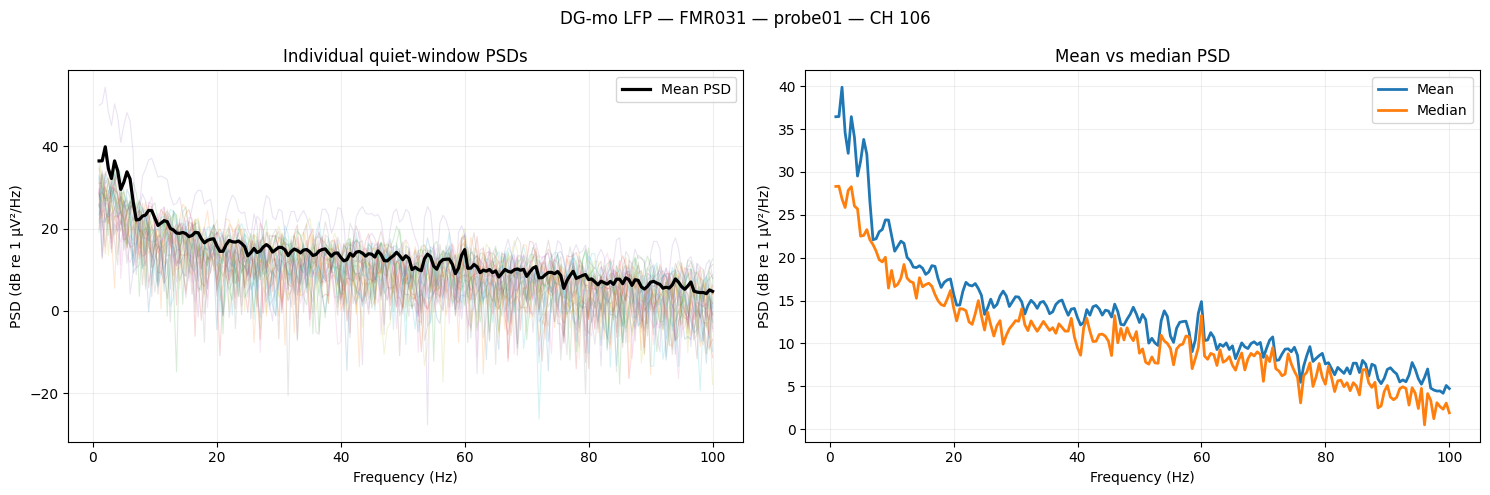

In [24]:

# STEP 9 — Compare individual, mean and median spectra

import matplotlib.pyplot as plt

mask = (
    (frequencies >= 1) &
    (frequencies <= 100)
)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5)
)

# Individual spectra
for psd in all_psd:
    axes[0].plot(
        frequencies[mask],
        10 * np.log10(np.maximum(psd[mask], 1e-20)),
        alpha=0.18,
        linewidth=0.8
    )

axes[0].plot(
    frequencies[mask],
    10 * np.log10(np.maximum(mean_psd[mask], 1e-20)),
    color="black",
    linewidth=2.3,
    label="Mean PSD"
)

axes[0].set_title("Individual quiet-window PSDs")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("PSD (dB re 1 µV²/Hz)")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Mean vs median
axes[1].plot(
    frequencies[mask],
    10 * np.log10(np.maximum(mean_psd[mask], 1e-20)),
    linewidth=2,
    label="Mean"
)

axes[1].plot(
    frequencies[mask],
    10 * np.log10(np.maximum(median_psd[mask], 1e-20)),
    linewidth=2,
    label="Median"
)

axes[1].set_title("Mean vs median PSD")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("PSD (dB re 1 µV²/Hz)")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.suptitle(
    f"DG-mo LFP — FMR031 — {PILOT_PROBE} — CH {CH}"
)
plt.tight_layout()
plt.show()


,window,Delta,Theta,Alpha-like,Beta,Low gamma,High gamma
0,1,1516.226734,514.535980,178.571777,640.716305,416.534734,166.980540
1,2,1462.930206,1303.876122,292.555748,603.009374,283.370304,72.790234
2,3,3168.484772,2302.074402,688.046844,1020.057408,555.563464,216.645629
3,4,1575.767635,1301.800362,604.204653,515.837043,296.111857,113.771739
4,5,733.179253,451.047642,789.925762,676.760245,360.392255,222.458264
5,6,3464.532425,1210.224646,222.748040,683.251044,412.570572,140.527978
6,7,2062.004395,714.662236,185.145541,513.298200,363.381563,208.433295
7,8,1107.315170,340.858709,260.758476,640.904343,386.581325,282.444379
8,9,3199.542953,1355.147211,263.019603,762.919175,322.542188,165.306435
9,10,1762.532043,839.643337,166.204709,676.798132,305.548822,259.465604


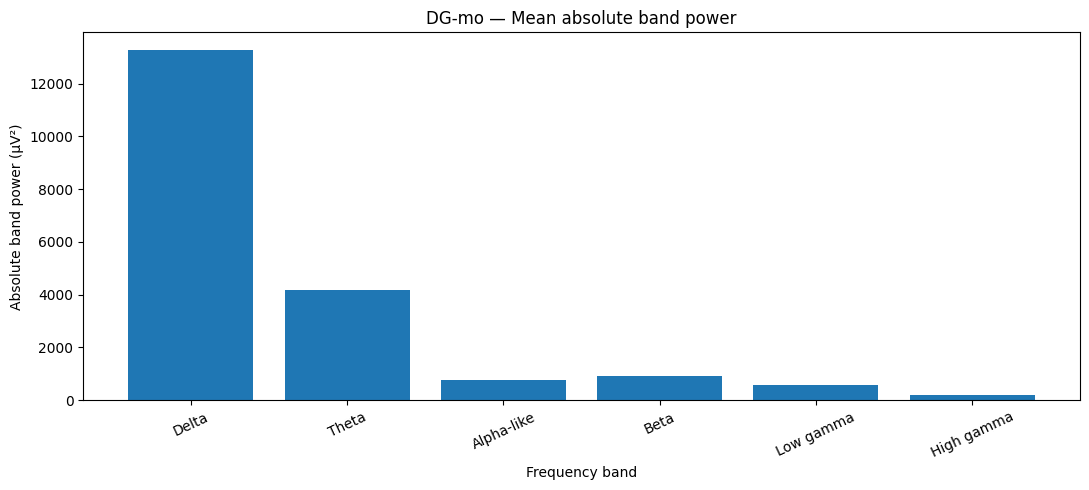


Mean absolute band powers:
Delta         13275.900
Theta          4192.254
Alpha-like      765.086
Beta            933.766
Low gamma       577.885
High gamma      211.023


In [25]:

# STEP 10 — Calculate band powers for every window

BANDS = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha-like": (8, 12),
    "Beta": (12, 30),
    "Low gamma": (30, 55),
    "High gamma": (65, 100)
}

band_rows = []

for window_idx, psd in enumerate(all_psd):

    row = {"window": window_idx + 1}

    for band, (fmin, fmax) in BANDS.items():
        band_mask = (
            (frequencies >= fmin) &
            (frequencies <= fmax)
        )

        power = np.trapezoid(
            psd[band_mask],
            frequencies[band_mask]
        )

        row[band] = power

    band_rows.append(row)

band_df = pd.DataFrame(band_rows)

band_means = band_df[
    list(BANDS.keys())
].mean()

display(band_df)

# Plot band power
plt.figure(figsize=(11, 5))

plt.bar(
    band_means.index,
    band_means.values
)

plt.ylabel("Absolute band power (µV²)")
plt.xlabel("Frequency band")
plt.title("DG-mo — Mean absolute band power")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print("\nMean absolute band powers:")
print(band_means.round(3).to_string())


Median RMS: 104.58 µV
Robust sigma: 32.02 µV
QC threshold: 296.67 µV
Flagged windows: 1


,window,start_s,rms_uv,peak_to_peak_uv
24,25,3595.797701,1401.400757,4523.4375


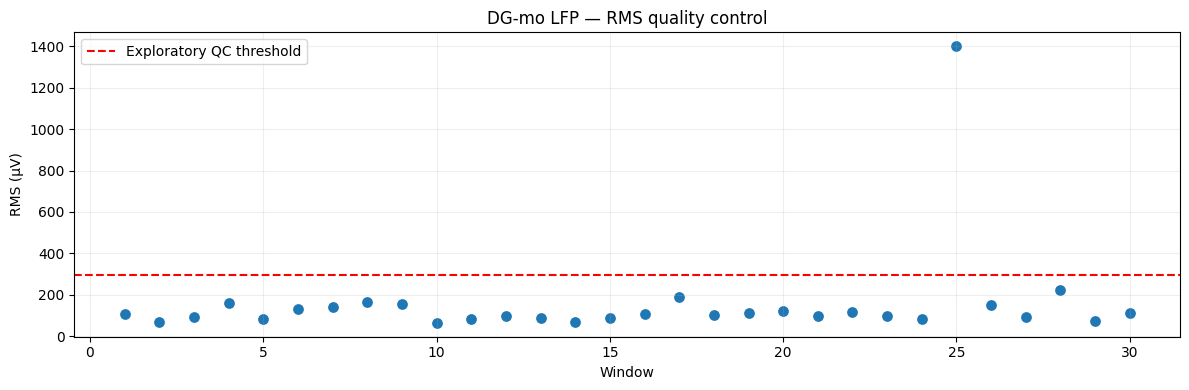

In [26]:

# STEP 11 — Detect high-amplitude LFP outliers
# This is exploratory QC, not the final artifact-rejection rule.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

valid_qc = qc_df.loc[
    qc_df["status"] == "valid"
].copy().reset_index(drop=True)

rms = valid_qc["rms_uv"].to_numpy()

median_rms = np.median(rms)
mad_rms = np.median(np.abs(rms - median_rms))

# Robust estimate of standard deviation
robust_sigma = 1.4826 * mad_rms
threshold = median_rms + 6 * robust_sigma

valid_qc["qc_outlier"] = rms > threshold

print(f"Median RMS: {median_rms:.2f} µV")
print(f"Robust sigma: {robust_sigma:.2f} µV")
print(f"QC threshold: {threshold:.2f} µV")
print("Flagged windows:",
      valid_qc["qc_outlier"].sum())

display(
    valid_qc.loc[
        valid_qc["qc_outlier"],
        ["window", "start_s", "rms_uv",
         "peak_to_peak_uv"]
    ]
)

plt.figure(figsize=(12, 4))

plt.scatter(
    valid_qc["window"],
    valid_qc["rms_uv"],
    s=45
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Exploratory QC threshold"
)

plt.xlabel("Window")
plt.ylabel("RMS (µV)")
plt.title("DG-mo LFP — RMS quality control")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


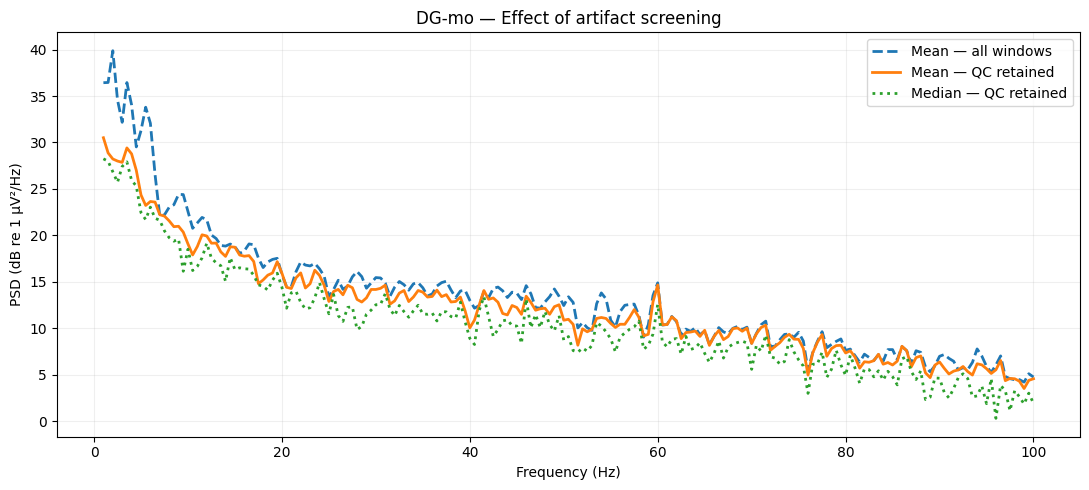

Original windows: 30
QC-retained windows: 29


In [27]:

# STEP 12 — Compare PSD before and after QC

assert len(valid_qc) == len(all_psd)

keep = ~valid_qc["qc_outlier"].to_numpy()

if keep.sum() < 3:
    raise RuntimeError("Too few windows remaining after QC.")

psd_clean = all_psd[keep]

mean_before = np.mean(all_psd, axis=0)
mean_after = np.mean(psd_clean, axis=0)
median_after = np.median(psd_clean, axis=0)

mask = (
    (frequencies >= 1) &
    (frequencies <= 100)
)

plt.figure(figsize=(11, 5))

for spectrum, label, style in [
    (mean_before, "Mean — all windows", "--"),
    (mean_after, "Mean — QC retained", "-"),
    (median_after, "Median — QC retained", ":")
]:
    plt.plot(
        frequencies[mask],
        10 * np.log10(
            np.maximum(spectrum[mask], 1e-20)
        ),
        linestyle=style,
        linewidth=2,
        label=label
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB re 1 µV²/Hz)")
plt.title("DG-mo — Effect of artifact screening")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Original windows:", len(all_psd))
print("QC-retained windows:", len(psd_clean))


,Band,Before_QC,After_QC,Change_percent
0,Delta,13275.90,2244.56,-83.09
1,Theta,4192.25,1109.47,-73.54
2,Alpha-like,765.09,398.92,-47.86
3,Beta,933.77,748.71,-19.82
4,Low gamma,577.89,446.56,-22.73
5,High gamma,211.02,192.90,-8.59


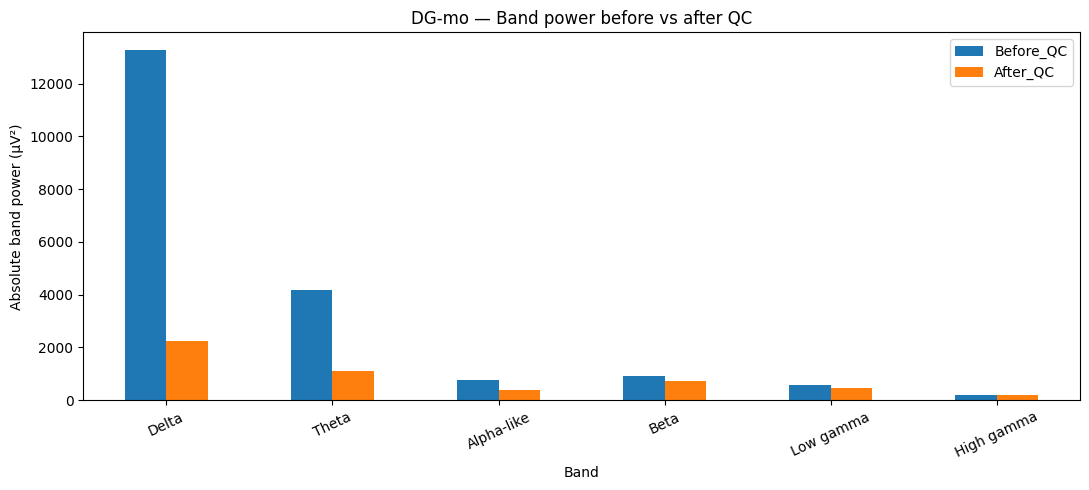

In [28]:

# STEP 13 — Quantify band-power sensitivity to QC

bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha-like": (8, 12),
    "Beta": (12, 30),
    "Low gamma": (30, 55),
    "High gamma": (65, 100)
}

rows = []

for name, (low, high) in bands.items():

    mask = (
        (frequencies >= low) &
        (frequencies <= high)
    )

    before = np.trapezoid(
        mean_before[mask],
        frequencies[mask]
    )

    after = np.trapezoid(
        mean_after[mask],
        frequencies[mask]
    )

    rows.append({
        "Band": name,
        "Before_QC": before,
        "After_QC": after,
        "Change_percent": (
            100 * (after / before - 1)
            if before > 0 else np.nan
        )
    })

comparison = pd.DataFrame(rows)

display(comparison.round(2))

ax = comparison.set_index("Band")[
    ["Before_QC", "After_QC"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_ylabel("Absolute band power (µV²)")
ax.set_title("DG-mo — Band power before vs after QC")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


In [29]:

# STEP 14 — Tukey artifact rejection based on LFP RMS
# Conservative upper fence: Q3 + 3 * IQR

import numpy as np
import pandas as pd

qc_tukey = qc_df.loc[
    qc_df["status"] == "valid"
].copy().reset_index(drop=True)

rms = qc_tukey["rms_uv"].to_numpy(dtype=float)

Q1 = np.percentile(rms, 25)
Q3 = np.percentile(rms, 75)
IQR = Q3 - Q1

TUKEY_K = 3.0
upper_fence = Q3 + TUKEY_K * IQR

qc_tukey["artifact_tukey"] = (
    qc_tukey["rms_uv"] > upper_fence
)

print(f"Q1: {Q1:.2f} µV")
print(f"Q3: {Q3:.2f} µV")
print(f"IQR: {IQR:.2f} µV")
print(f"Upper fence: {upper_fence:.2f} µV")

print("\nRejected windows:")
display(qc_tukey.loc[
    qc_tukey["artifact_tukey"],
    ["window", "start_s", "rms_uv", "peak_to_peak_uv"]
])

print(
    "\nRejection rate:",
    f"{100 * qc_tukey['artifact_tukey'].mean():.1f}%"
)


Q1: 86.19 µV
Q3: 138.82 µV
IQR: 52.63 µV
Upper fence: 296.72 µV

Rejected windows:


,window,start_s,rms_uv,peak_to_peak_uv
24,25,3595.797701,1401.400757,4523.4375



Rejection rate: 3.3%


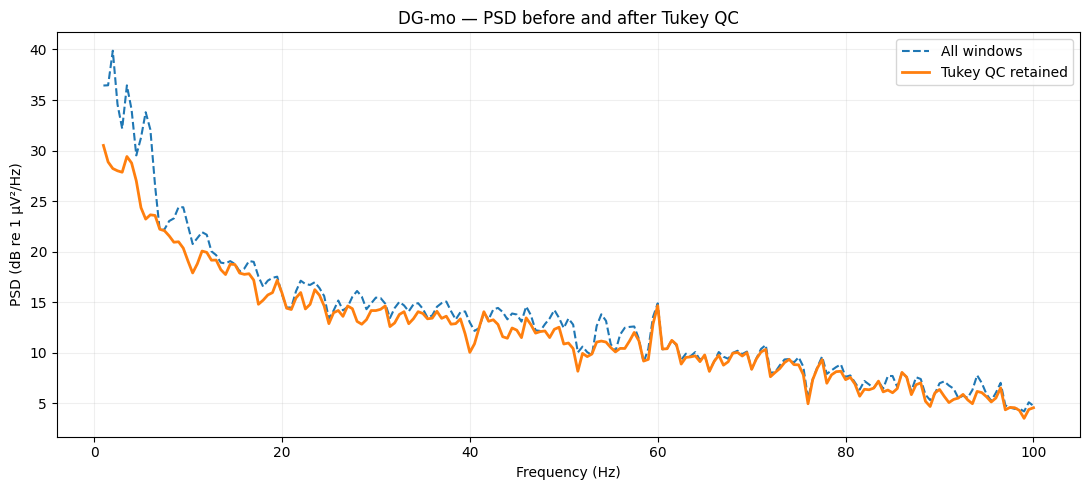

,Band,Before_QC,After_QC,Change_%
0,Delta,13275.90,2244.56,-83.09
1,Theta,4192.25,1109.47,-73.54
2,Alpha-like,765.09,398.92,-47.86
3,Beta,933.77,748.71,-19.82
4,Low gamma,577.89,446.56,-22.73
5,High gamma,211.02,192.90,-8.59


In [30]:

# STEP 15 — Recalculate PSD after Tukey QC

from scipy.signal import welch
import matplotlib.pyplot as plt

assert len(qc_tukey) == len(all_psd)

keep = ~qc_tukey["artifact_tukey"].to_numpy()

psd_tukey = all_psd[keep]

mean_all = all_psd.mean(axis=0)
mean_tukey = psd_tukey.mean(axis=0)

mask = (frequencies >= 1) & (frequencies <= 100)

plt.figure(figsize=(11, 5))

plt.plot(
    frequencies[mask],
    10 * np.log10(np.maximum(mean_all[mask], 1e-20)),
    label="All windows",
    linestyle="--"
)

plt.plot(
    frequencies[mask],
    10 * np.log10(np.maximum(mean_tukey[mask], 1e-20)),
    label="Tukey QC retained",
    linewidth=2
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB re 1 µV²/Hz)")
plt.title("DG-mo — PSD before and after Tukey QC")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Compare integrated power across frequency bands.
rows = []

for band, (low, high) in BANDS.items():
    band_mask = (
        (frequencies >= low) &
        (frequencies <= high)
    )

    before = np.trapezoid(
        mean_all[band_mask],
        frequencies[band_mask]
    )

    after = np.trapezoid(
        mean_tukey[band_mask],
        frequencies[band_mask]
    )

    rows.append({
        "Band": band,
        "Before_QC": before,
        "After_QC": after,
        "Change_%": 100 * (after / before - 1)
    })

tukey_comparison = pd.DataFrame(rows)

display(tukey_comparison.round(2))


In [31]:

# STEP 22 — Prepare all Dentate Gyrus contacts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from iblatlas.regions import BrainRegions

PILOT_PROBE = "probe01"
LAYERS = ["DG-mo", "DG-sg", "DG-po"]

# Load channel anatomy from the existing ALF dataset.
channels = one.load_object(
    eid,
    "channels",
    collection=f"alf/{PILOT_PROBE}/pykilosort"
)

br = BrainRegions()

atlas_ids = np.asarray(
    channels["brainLocationIds_ccf_2017"],
    dtype=int
)

acronyms = np.asarray(br.id2acronym(atlas_ids))
raw_indices = np.asarray(channels["rawInd"], dtype=int)

# Keep only contacts anatomically assigned to DG.
dg_mask = np.isin(acronyms, LAYERS)

dg_channels = raw_indices[dg_mask]
dg_labels = acronyms[dg_mask]

# Sort contacts by raw recording channel index.
order = np.argsort(dg_channels)

dg_channels = dg_channels[order]
dg_labels = dg_labels[order]

# Store an anatomical table for later processing.
dg_channel_table = pd.DataFrame({
    "raw_channel": dg_channels,
    "layer": dg_labels
})

print("Total DG contacts:", len(dg_channels))
print("\nContacts per layer:")
print(dg_channel_table["layer"].value_counts())

display(dg_channel_table.head(10))

assert len(dg_channels) == 184
assert len(selected_windows) == 30
assert np.isclose(WINDOW_S, 2.0)
assert dg_channels.min() >= 0
assert dg_channels.max() < sr_lf.nc - sr_lf.nsync


Total DG contacts: 184

Contacts per layer:
layer
DG-mo    108
DG-sg     56
DG-po     20
Name: count, dtype: int64


,raw_channel,layer
0,0,DG-mo
1,1,DG-mo
2,2,DG-mo
3,3,DG-mo
4,4,DG-mo
5,5,DG-mo
6,6,DG-mo
7,7,DG-mo
8,8,DG-mo
9,9,DG-mo


In [32]:

# STEP 23 — Stream multichannel DG LFP and compute PSD

from scipy.signal import welch

fs = float(sr_lf.fs)
n_samples = int(round(WINDOW_S * fs))

N_FREQ_MAX = 100.0

rms_matrix = []
ptp_matrix = []
psd_windows = []

for i, (t0, t1) in enumerate(selected_windows):

    # Convert session time to probe-local time.
    probe_t0 = float(
        ssl.timesprobe2times(
            float(t0),
            direction="reverse"
        )
    )

    s0 = int(round(probe_t0 * fs))
    s1 = s0 + n_samples

    # Stream all neural channels in one request.
    # The final channel is the synchronization channel.
    raw_block = np.asarray(
        sr_lf[s0:s1, :384]
    )

    if raw_block.shape != (n_samples, 384):
        raise RuntimeError(
            f"Unexpected LFP shape at window {i+1}: "
            f"{raw_block.shape}"
        )

    # Extract DG channels and convert volts to microvolts.
    signals_uv = (
        raw_block[:, dg_channels].astype(np.float64)
        * 1e6
    )

    if not np.all(np.isfinite(signals_uv)):
        raise RuntimeError(
            f"Non-finite data at window {i+1}"
        )

    # Per-channel QC measurements.
    rms = np.std(signals_uv, axis=0)
    ptp = np.ptp(signals_uv, axis=0)

    # Calculate a PSD for every DG channel.
    # Axis 0 represents time; axis 1 represents channels.
    freqs, psd = welch(
        signals_uv,
        fs=fs,
        window="hann",
        nperseg=n_samples,
        noverlap=0,
        detrend="linear",
        scaling="density",
        axis=0
    )

    # Retain frequencies up to 100 Hz.
    freq_mask = freqs <= N_FREQ_MAX

    psd_windows.append(
        psd[freq_mask, :].astype(np.float32)
    )

    rms_matrix.append(rms)
    ptp_matrix.append(ptp)

    if (i + 1) % 5 == 0:
        print(f"Processed {i+1}/30 windows")

# Final shapes:
# PSD: windows x frequencies x channels
# RMS/PTP: windows x channels

psd_dg = np.stack(psd_windows, axis=0)
rms_dg = np.stack(rms_matrix, axis=0)
ptp_dg = np.stack(ptp_matrix, axis=0)

freqs_dg = freqs[freqs <= N_FREQ_MAX]

print("\nProcessing complete")
print("PSD shape:", psd_dg.shape)
print("RMS shape:", rms_dg.shape)
print("Frequency resolution:", np.diff(freqs_dg)[0], "Hz")
print("Memory usage:",
      round(psd_dg.nbytes / 1024**2, 1), "MB")


2026-11-17 19:24:26 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:24:26 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:24:26 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:24:27 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:24:27 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


Processed 5/30 windows
2026-11-17 19:24:27 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


... (21 outputs left out)

2026-11-17 19:24:33 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:24:34 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


2026-11-17 19:24:34 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


Processed 30/30 windows

Processing complete
PSD shape: (30, 201, 184)
RMS shape: (30, 184)
Frequency resolution: 0.5 Hz
Memory usage: 4.2 MB


In [33]:

# STEP 24 — Two-level Tukey QC for multichannel DG LFP

TUKEY_K = 3.0
N_WIN, N_CH = rms_dg.shape

def tukey_upper(values, k=3.0):
    q1, q3 = np.percentile(values, [25, 75])
    return q3 + k * (q3 - q1)

# Level 1: detect globally abnormal time windows.
# Use the median RMS within each anatomical layer.
shared_window_keep = np.ones(N_WIN, dtype=bool)

for layer in LAYERS:
    idx = np.where(dg_labels == layer)[0]

    layer_window_rms = np.median(
        rms_dg[:, idx],
        axis=1
    )

    threshold = tukey_upper(
        layer_window_rms,
        TUKEY_K
    )

    layer_keep = layer_window_rms <= threshold
    shared_window_keep &= layer_keep

    print(
        f"{layer}: threshold={threshold:.1f} µV, "
        f"flagged={np.sum(~layer_keep)}"
    )

print("\nGlobally rejected windows:",
      (np.where(~shared_window_keep)[0] + 1).tolist())

# Level 2: detect abnormal channel-window combinations.
channel_window_keep = np.ones(
    (N_WIN, N_CH),
    dtype=bool
)

for j in range(N_CH):
    # Estimate each contact's threshold from its own RMS.
    threshold = tukey_upper(
        rms_dg[shared_window_keep, j],
        TUKEY_K
    )

    channel_window_keep[:, j] = (
        rms_dg[:, j] <= threshold
    )

# Apply the shared time-window mask.
channel_window_keep &= shared_window_keep[:, None]

# Require sufficient surviving windows per channel.
MIN_VALID_FRACTION = 0.70

channel_valid_fraction = (
    channel_window_keep.sum(axis=0)
    / max(shared_window_keep.sum(), 1)
)

good_channels = (
    channel_valid_fraction >= MIN_VALID_FRACTION
)

# Exclude low-quality contacts from subsequent aggregation.
channel_window_keep[:, ~good_channels] = False

qc_rows = []

for layer in LAYERS:
    idx = np.where(dg_labels == layer)[0]

    qc_rows.append({
        "Layer": layer,
        "Total_channels": len(idx),
        "Retained_channels": int(
            good_channels[idx].sum()
        ),
        "Shared_windows": int(
            shared_window_keep.sum()
        ),
        "Accepted_channel_windows": int(
            channel_window_keep[:, idx].sum()
        )
    })

dg_qc_summary = pd.DataFrame(qc_rows)
display(dg_qc_summary)

print("\nTotal accepted channel-window combinations:",
      channel_window_keep.sum())

if shared_window_keep.sum() < 10:
    raise RuntimeError(
        "Too few shared windows remain after QC."
    )

for layer in LAYERS:
    idx = np.where(dg_labels == layer)[0]
    if not good_channels[idx].any():
        raise RuntimeError(
            f"No usable channels remain in {layer}"
        )


DG-mo: threshold=177.3 µV, flagged=3
DG-sg: threshold=203.6 µV, flagged=2
DG-po: threshold=136.3 µV, flagged=4

Globally rejected windows: [6, 7, 25, 28]


,Layer,Total_channels,Retained_channels,Shared_windows,Accepted_channel_windows
0,DG-mo,108,108,26,2765
1,DG-sg,56,56,26,1424
2,DG-po,20,20,26,500



Total accepted channel-window combinations: 4689


In [34]:

# STEP 25 — Aggregate contact PSDs within DG layers

layer_spectra = {}
contact_mean_psd = np.full(
    (len(freqs_dg), N_CH),
    np.nan,
    dtype=float
)

for j in range(N_CH):
    valid = channel_window_keep[:, j]

    if valid.any():
        contact_mean_psd[:, j] = (
            psd_dg[valid, :, j].mean(axis=0)
        )

for layer in LAYERS:
    idx = np.where(
        (dg_labels == layer) & good_channels
    )[0]

    spectra = contact_mean_psd[:, idx]

    layer_spectra[layer] = {
        "median": np.nanmedian(spectra, axis=1),
        "mean": np.nanmean(spectra, axis=1),
        "n_channels": len(idx)
    }

    print(
        f"{layer}: {len(idx)} retained contacts"
    )


DG-mo: 108 retained contacts
DG-sg: 56 retained contacts
DG-po: 20 retained contacts


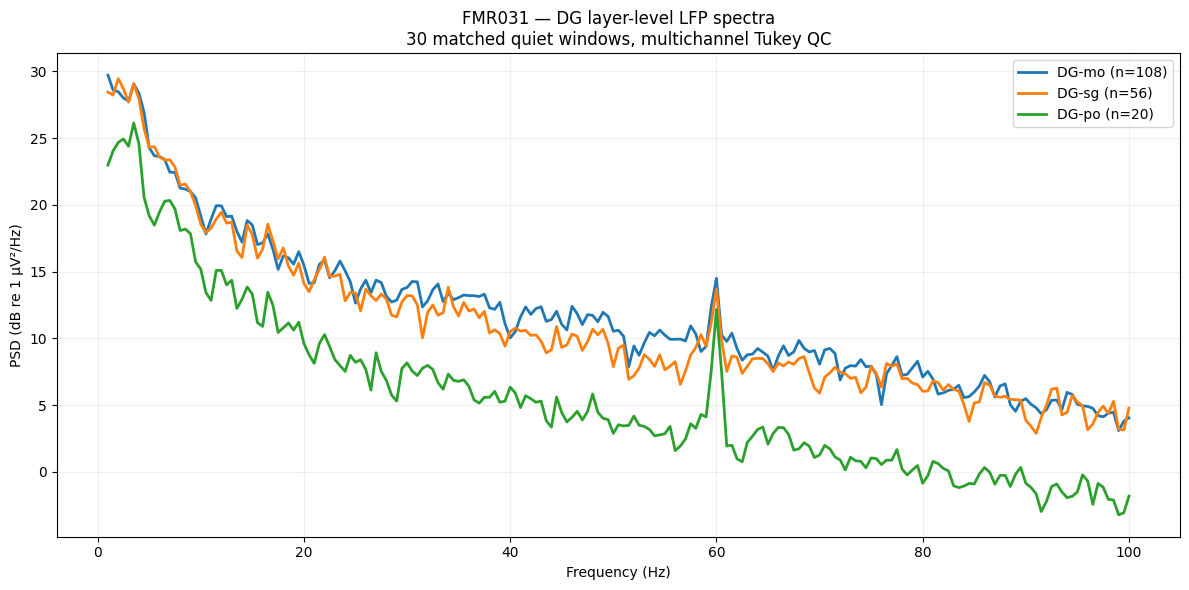

In [35]:

# STEP 26 — Plot layer-level PSD comparison

plt.figure(figsize=(12, 6))

mask = (
    (freqs_dg >= 1) &
    (freqs_dg <= 100)
)

for layer in LAYERS:
    spectrum = layer_spectra[layer]["median"]

    plt.plot(
        freqs_dg[mask],
        10 * np.log10(
            np.maximum(spectrum[mask], 1e-20)
        ),
        linewidth=2,
        label=(
            f"{layer} "
            f"(n={layer_spectra[layer]['n_channels']})"
        )
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB re 1 µV²/Hz)")
plt.title(
    "FMR031 — DG layer-level LFP spectra\n"
    "30 matched quiet windows, multichannel Tukey QC"
)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()


In [36]:

# STEP 27 — Calculate per-contact band powers

BANDS = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha-like": (8, 12),
    "Beta": (12, 30),
    "Low gamma": (30, 55),
    "High gamma": (65, 100)
}

def band_integral(spectrum, freqs, low, high):
    mask = (freqs >= low) & (freqs <= high)
    return float(
        np.trapezoid(
            spectrum[mask],
            freqs[mask]
        )
    )

power_rows = []

for j, channel in enumerate(dg_channels):

    if not good_channels[j]:
        continue

    layer = dg_labels[j]
    spectrum = contact_mean_psd[:, j]

    # Exclude the 55-65 Hz interval from total power.
    total_power = (
        band_integral(spectrum, freqs_dg, 1, 55)
        + band_integral(spectrum, freqs_dg, 65, 100)
    )

    for band, (low, high) in BANDS.items():
        absolute = band_integral(
            spectrum, freqs_dg, low, high
        )

        relative = (
            100 * absolute / total_power
            if total_power > 0 else np.nan
        )

        power_rows.append({
            "subject": "FMR031",
            "probe": PILOT_PROBE,
            "layer": layer,
            "channel": int(channel),
            "band": band,
            "absolute_uv2": absolute,
            "relative_percent": relative,
            "n_valid_windows": int(
                channel_window_keep[:, j].sum()
            )
        })

dg_contact_power = pd.DataFrame(power_rows)

# Aggregate contacts within each anatomical layer.
dg_layer_power = (
    dg_contact_power
    .groupby(["layer", "band"], as_index=False)
    .agg(
        absolute_uv2=("absolute_uv2", "median"),
        relative_percent=("relative_percent", "median"),
        n_channels=("channel", "nunique")
    )
)

print("Absolute band power (µV²):")
display(
    dg_layer_power.pivot(
        index="band",
        columns="layer",
        values="absolute_uv2"
    ).reindex(list(BANDS)).round(2)
)

print("Relative band power (%):")
display(
    dg_layer_power.pivot(
        index="band",
        columns="layer",
        values="relative_percent"
    ).reindex(list(BANDS)).round(2)
)


Absolute band power (µV²):


layer,DG-mo,DG-po,DG-sg
band,,,
Delta,2196.06,884.77,2170.07
Theta,1117.30,416.62,1071.45
Alpha-like,402.26,158.20,377.82
Beta,726.99,202.82,642.07
Low gamma,404.05,85.76,293.10
High gamma,179.74,36.36,150.11


Relative band power (%):


layer,DG-mo,DG-po,DG-sg
band,,,
Delta,43.93,49.85,49.59
Theta,22.53,23.12,22.92
Alpha-like,8.20,8.85,8.62
Beta,12.97,11.54,11.51
Low gamma,6.74,4.81,4.88
High gamma,3.12,2.03,2.25


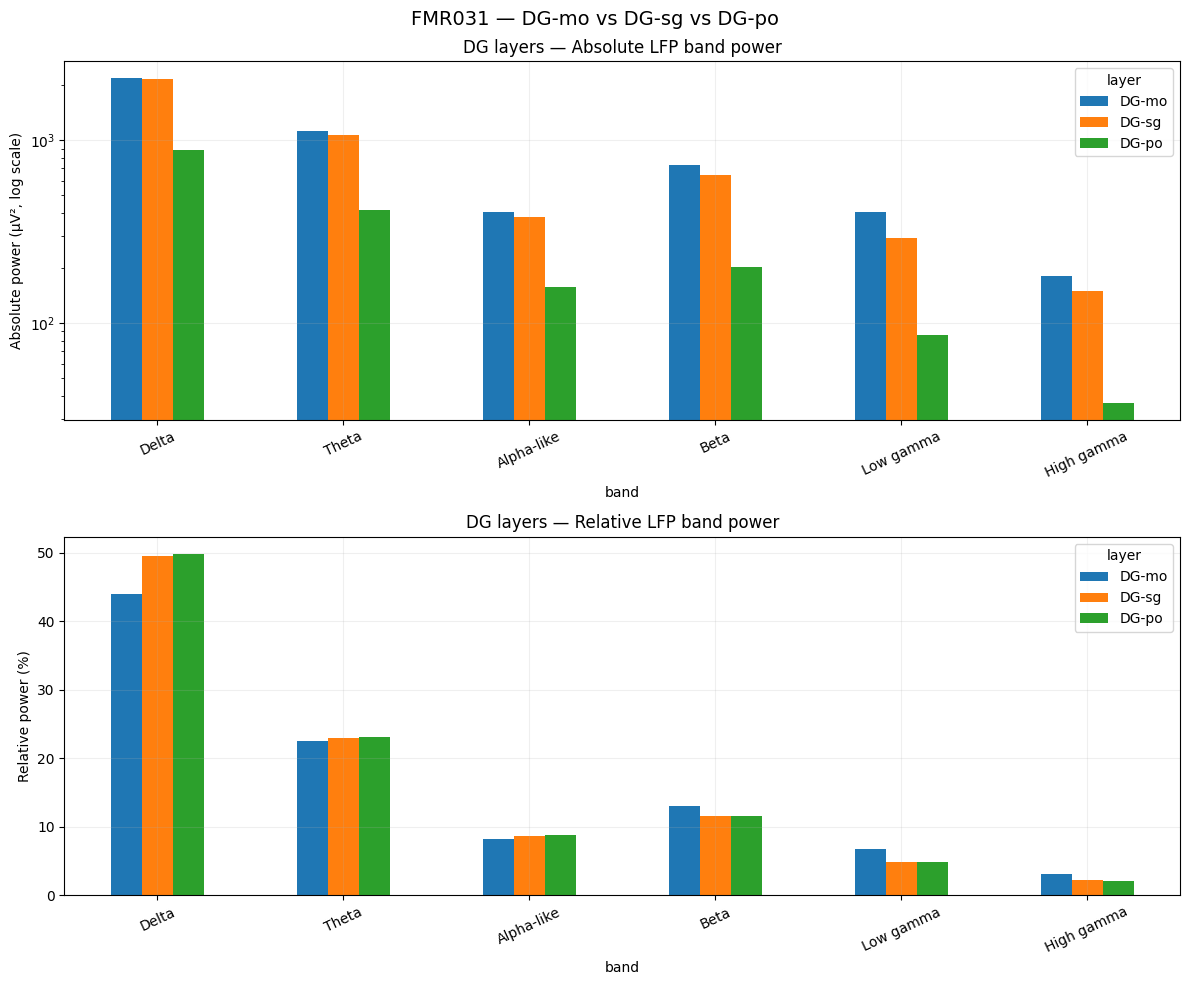

In [37]:

# STEP 28 — Plot DG layer band-power comparisons

absolute = dg_layer_power.pivot(
    index="band",
    columns="layer",
    values="absolute_uv2"
).reindex(list(BANDS))

relative = dg_layer_power.pivot(
    index="band",
    columns="layer",
    values="relative_percent"
).reindex(list(BANDS))

fig, axes = plt.subplots(
    2, 1, figsize=(12, 10)
)

absolute[LAYERS].plot(
    kind="bar",
    ax=axes[0],
    logy=True
)

axes[0].set_ylabel("Absolute power (µV², log scale)")
axes[0].set_title("DG layers — Absolute LFP band power")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(alpha=0.2)

relative[LAYERS].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_ylabel("Relative power (%)")
axes[1].set_title("DG layers — Relative LFP band power")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(alpha=0.2)

plt.suptitle(
    "FMR031 — DG-mo vs DG-sg vs DG-po",
    fontsize=14
)

plt.tight_layout()
plt.show()
